# TN3K · Base U-Net · epoch 27

İlk hücredeki **`DATASET_ROOT`** alanını boş bırakırsan Kaggle’daki TN3K sürüm 2 kullanılır. Veriyi başka bir konumda tutuyorsan dört veri klasörünün doğrudan içinde bulunduğu dizini yaz. Beklenen alt klasörler `trainval-image`, `trainval-mask`, `test-image` ve `test-mask`.

Hücreleri 1’den 8’e sırayla çalıştır. Drive izni istenirse proje dosyalarının bulunduğu hesabı seç. Bir kontrol durursa hücre başlığını, yazdırılan son satırları ve hata mesajını paylaş.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1 · Ayar ve Drive bağlantısı

Drive’ı bağlar ve kullanılacak dosya yollarını tanımlar.

In [1]:
DATASET_ROOT = ""  # Boşsa aynı Kaggle sürümünü kullan.

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

project = Path("/content/drive/MyDrive/TN3K")
base = project / "BaseUNet"
checkpoint_path = base / "Colab_Indirilenler" / "best.pt"
history_path = checkpoint_path.with_name("history.csv")
windows_manifest = base / "Windows_Yerel" / "split_manifest.csv"
colab_manifest = checkpoint_path.with_name("split_manifest.csv")
results_root = base / "Test_Sonuclari"

Mounted at /content/drive


## 2 · Ortam ve veri yolları

Gerekli dosyaları bulur, cihazı seçer ve dört veri klasörünü kontrol eder.

In [2]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch>=2.3", "pandas": "pandas", "numpy": "numpy",
            "PIL": "Pillow", "scipy": "scipy", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "tqdm": "tqdm"}
if not DATASET_ROOT.strip():
    packages["kagglehub"] = "kagglehub"
missing_packages = [package for module, package in packages.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_packages])

from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from typing import Any, Mapping, Sequence
from uuid import uuid4
import hashlib
import json
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from scipy import ndimage as ndi
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from torch.utils.data import DataLoader, Dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
for label, path in [("Checkpoint", checkpoint_path), ("Geçmiş", history_path),
                    ("Windows manifesti", windows_manifest), ("Colab manifest adayı", colab_manifest)]:
    print(f"{label}: {path}")

for path in (checkpoint_path, history_path):
    if not path.is_file():
        raise FileNotFoundError(f"Gerekli dosya bulunamadı: {path}")
if not (windows_manifest.is_file() or colab_manifest.is_file()):
    raise FileNotFoundError(f"Aday ayrım dosyaları bulunamadı: {windows_manifest} veya {colab_manifest}")

if DATASET_ROOT.strip():
    data_root = Path(DATASET_ROOT.strip()).expanduser().resolve()
else:
    import kagglehub
    data_root = Path(kagglehub.dataset_download(
        "tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2"
    )).resolve()

print("TN3K veri kökü:", data_root)
expected_counts = {"trainval-image": 2879, "trainval-mask": 2879,
                   "test-image": 614, "test-mask": 614}
files = {}
for name, expected in expected_counts.items():
    folder = data_root / name
    if not folder.is_dir():
        raise FileNotFoundError(f"TN3K alt klasörü bulunamadı: {folder}")
    files[name] = sorted(folder.glob("*.jpg"))
    print(f"{name}: {len(files[name])} JPG")
    if len(files[name]) != expected:
        raise ValueError(f"{folder}: {expected} JPG bekleniyordu, {len(files[name])} bulundu.")

Cihaz: CPU
Checkpoint: /content/drive/MyDrive/TN3K/BaseUNet/Colab_Indirilenler/best.pt
Geçmiş: /content/drive/MyDrive/TN3K/BaseUNet/Colab_Indirilenler/history.csv
Windows manifesti: /content/drive/MyDrive/TN3K/BaseUNet/Windows_Yerel/split_manifest.csv
Colab manifest adayı: /content/drive/MyDrive/TN3K/BaseUNet/Colab_Indirilenler/split_manifest.csv
Using Colab cache for faster access to the 'tn3k-thyroid-nodule-region-segmentation-dataset' dataset.
TN3K veri kökü: /kaggle/input/tn3k-thyroid-nodule-region-segmentation-dataset
trainval-image: 2879 JPG
trainval-mask: 2879 JPG
test-image: 614 JPG
test-mask: 614 JPG


## 3 · Checkpoint ve eğitim geçmişi

Epoch 27 ağırlığını ve doğrulama skorunu geçmiş CSV’siyle kontrol eder. Deney ayarlarını checkpoint’ten okur.

In [3]:
@dataclass(frozen=True)
class Config:
    """Bütün deney seçimleri; EDA ROOT ve SEED değerlerini devralır."""
    root: Path
    seed: int
    output_root: Path = Path.cwd() / 'tn3k_training'
    run_name: str = 'native_unet_image_split_01'
    pad_multiple: int = 32
    fixed_input_hw: tuple[int, int] | None = None  # Alternatif: (832, 1472); resize DEĞİL.
    input_channels: int = 1
    mask_threshold: int = 128
    intensity_scale: float = 255.0
    padding_value: float = 0.0
    foreground_value: float = 1.0
    prediction_threshold: float = 0.5
    validation_fraction: float = 0.20
    normalization: str = 'scale'  # 'scale' veya ayrı ablation için 'zscore'.
    horizontal_flip_probability: float = 0.5
    batch_size: int = 1
    num_workers: int = 0  # Notebook / Windows / Colab için güvenli varsayılan.
    pin_memory: bool = True
    base_channels: int = 16
    depth: int = 4
    norm_groups: int = 4
    conv_kernel: int = 3
    downsample_factor: int = 2
    epochs: int = 100
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    gradient_accumulation: int = 4
    gradient_clip: float = 1.0
    loss_kind: str = 'bce_dice'  # Alternatif: 'focal_dice'.
    pixel_loss_weight: float = 0.5
    focal_alpha: float = 0.75
    focal_gamma: float = 2.0
    epsilon: float = 1e-6
    lr_factor: float = 0.5
    lr_patience: int = 5
    min_learning_rate: float = 1e-6
    early_stopping_patience: int = 20
    early_stopping_min_delta: float = 1e-4
    use_amp: bool = True
    activation_checkpointing: bool = True
    deterministic: bool = True
    device: str = 'auto'
    cublas_workspace_config: str = ':4096:8'
    hd_percentile: float = 95.0
    surface_connectivity: int = 1
    small_area_quantile: float = 0.25
    sanity_examples: int = 4
    prediction_examples: int = 4
    overlay_alpha: float = 0.4
    figure_dpi: int = 140

    @property
    def input_shape(self) -> tuple[int, int | None, int | None]:
        """PyTorch C,H,W; None özgün boyuta göre dinamik padding demektir."""
        return (self.input_channels, *(self.fixed_input_hw or (None, None)))

    @property
    def run_dir(self) -> Path:
        return self.output_root / self.run_name

    @property
    def manifest_path(self) -> Path:
        return self.run_dir / 'split_manifest.csv'

    @property
    def best_checkpoint_path(self) -> Path:
        return self.run_dir / 'best.pt'

    @property
    def history_path(self) -> Path:
        return self.run_dir / 'history.csv'

    @property
    def test_dir(self) -> Path:
        return self.run_dir / 'final_test'

    def validate(self) -> None:
        """Gizli resize/fallback yerine geçersiz ayarları açıkça reddet."""
        if not self.root.is_dir():
            raise ValueError(f'EDA ROOT bulunamadı: {self.root}')
        if self.batch_size != 1:
            raise ValueError('Bu değişken boyutlu uygulamada batch_size=1; etkili batch için accumulation kullan.')
        divisor = self.downsample_factor ** self.depth
        if self.downsample_factor != 2 or self.depth < 1 or self.pad_multiple % divisor:
            raise ValueError('pad_multiple, 2**depth ile tam bölünmeli; downsample_factor=2 olmalı.')
        if self.base_channels < self.norm_groups or self.base_channels % self.norm_groups:
            raise ValueError('base_channels norm_groups ile bölünebilmeli.')
        if self.conv_kernel % 2 == 0:
            raise ValueError('Aynı boyutu korumak için tek sayılı convolution kernel gerekli.')
        if self.padding_value != 0.0 or self.foreground_value != 1.0 or self.input_channels != 1:
            raise ValueError('Bu sürüm grayscale giriş, sıfır padding ve {0,1} maske kullanır.')
        if not 0 < self.validation_fraction < 1 or not 0 < self.prediction_threshold < 1:
            raise ValueError('Split ve tahmin eşikleri (0,1) aralığında olmalı.')
        if not 0 <= self.horizontal_flip_probability <= 1 or not 0 <= self.pixel_loss_weight <= 1:
            raise ValueError('Olasılık/ağırlık aralığı [0,1] olmalı.')
        if self.normalization not in ('scale', 'zscore') or self.loss_kind not in ('bce_dice', 'focal_dice'):
            raise ValueError('Bilinmeyen normalizasyon veya loss.')
        if min(self.epochs, self.gradient_accumulation, self.early_stopping_patience) < 1:
            raise ValueError('Epoch, accumulation ve patience pozitif olmalı.')
        if self.fixed_input_hw and any(s <= 0 or s % self.pad_multiple for s in self.fixed_input_hw):
            raise ValueError('Sabit canvas boyutları pozitif pad_multiple katları olmalı.')

def config_payload(config: Config) -> dict[str, Any]:
    """JSON ve güvenli checkpoint için yalnız ilkel türler üret."""
    return {key: str(value) if isinstance(value, Path) else value for key, value in asdict(config).items()}


state = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
required = {"model_state", "config", "epoch", "best_val_dice", "manifest_hash", "small_area_cutoff"}
if missing := required.difference(state):
    raise ValueError(f"Checkpoint alanları eksik: {sorted(missing)}")
if state["epoch"] != 27:
    raise ValueError(f"Epoch 27 bekleniyordu, dosyada epoch {state['epoch']} var.")

saved_config = state["config"]
cfg = Config(**{**saved_config, "root": Path(saved_config["root"]),
                "output_root": Path(saved_config["output_root"])})
if config_payload(cfg) != saved_config:
    raise ValueError("Checkpoint ayarları orijinal Base U-Net yapılandırmasıyla eşleşmiyor.")

history = pd.read_csv(history_path)
best_rows = history.loc[history["epoch"].eq(state["epoch"])]
if len(best_rows) != 1 or not math.isclose(float(best_rows.iloc[0]["val_dice"]),
                                          state["best_val_dice"], rel_tol=0, abs_tol=1e-8):
    raise ValueError("Checkpoint epoch'u veya doğrulama Dice skoru history.csv ile eşleşmiyor.")
if not math.isclose(float(history["val_dice"].max()), state["best_val_dice"],
                    rel_tol=0, abs_tol=1e-8):
    raise ValueError("Checkpoint Dice skoru, history.csv dosyasının en yüksek doğrulama Dice skoru değil.")

print(f"Base U-Net · epoch {state['epoch']} | doğrulama Dice: {state['best_val_dice']:.6f}")
print(f"Doğrulama IoU: {best_rows.iloc[0]['val_iou']:.6f} | geçmişte son epoch: {history['epoch'].max()}")
print("Checkpoint'in beklediği manifest SHA-256:", state["manifest_hash"])

Base U-Net · epoch 27 | doğrulama Dice: 0.776388
Doğrulama IoU: 0.668326 | geçmişte son epoch: 31
Checkpoint'in beklediği manifest SHA-256: 8e7f07f36625f59bd0f233e8c4f84ecc4e0f181fbad77788c6513f1d4df6867b


## 4 · Veri ayrımını checkpoint ile eşleştir

Aday dosyaların hash’ini kontrol eder ve indirilen veriden orijinal ayrımı üretir. Test yalnız checkpoint’in beklediği tam dosya hash’i doğrulanırsa açılır.

In [4]:
def read_image_mask(image_path: str | Path, mask_path: str | Path, config: Config) -> tuple[np.ndarray, np.ndarray]:
    """EDA gibi PIL convert('L') kullan; önce maskeyi ikilileştir, resize yapma."""
    with Image.open(image_path) as image, Image.open(mask_path) as mask:
        if image.size != mask.size:
            raise ValueError(f'Görüntü/maske boyutu farklı: {image_path}')
        x = np.asarray(image.convert('L')).copy()
        y = (np.asarray(mask.convert('L')) >= config.mask_threshold).astype(np.uint8)
    return x, y


def build_training_table(eda_df: pd.DataFrame, eda_pairs: Mapping[str, Sequence[tuple[Path, Path]]],
                         eda_mask_df: pd.DataFrame, config: Config) -> pd.DataFrame:
    """EDA df şemasını koru; yalnız ek sütunlarla yeni training_df oluştur."""
    required = {'split', 'filename', 'width', 'height', 'same_size', 'image_path', 'mask_path'}
    if not required.issubset(eda_df.columns) or eda_df.duplicated(['split', 'filename']).any():
        raise ValueError('EDA df şeması eksik veya eşleştirme anahtarı yineleniyor.')
    if set(eda_df['split']) != {'trainval', 'test'} or not eda_df['same_size'].all():
        raise ValueError('EDA split/boyut denetimi başarısız.')
    table = eda_df.copy(deep=True).reset_index(drop=True)
    pairs = {(split, Path(ip).name): (Path(ip).resolve(), Path(mp).resolve())
             for split, items in eda_pairs.items() for ip, mp in items}
    if set(pairs) != set(zip(table['split'], table['filename'])):
        raise ValueError('df ve pair_paths aynı çiftleri içermiyor.')
    if eda_mask_df['file'].duplicated().any():
        raise ValueError('mask_df içinde yinelenen trainval dosyası var.')
    eda_areas = eda_mask_df.set_index('file')['foreground_pixels']
    if set(eda_areas.index) != set(table.loc[table['split'].eq('trainval'), 'filename']):
        raise ValueError('mask_df ve trainval dosyaları uyuşmuyor.')
    extra = []
    for row in table.itertuples():
        image_path, mask_path = pairs[(row.split, row.filename)]
        if image_path != Path(row.image_path).resolve() or mask_path != Path(row.mask_path).resolve():
            raise ValueError(f'df/pair_paths yol farkı: {row.filename}')
        if image_path.parent != (config.root / f'{row.split}-image').resolve():
            raise ValueError('Görüntü yolu EDA ROOT dışında.')
        x, y = read_image_mask(image_path, mask_path, config)
        if x.shape != (row.height, row.width):
            raise ValueError('Dosya boyutu EDA sonrasında değişmiş.')
        if row.split == 'trainval' and int(y.sum()) != int(eda_areas.loc[row.filename]):
            raise ValueError('Maske/eşik EDA mask_df alanıyla uyuşmuyor; EDA’yı yeniden çalıştır.')
        extra.append({'foreground_pixels': int(y.sum()), 'foreground_pct': float(y.mean() * 100),
                      'touches_border': bool(y[0].any() or y[-1].any() or y[:, 0].any() or y[:, -1].any()),
                      'image_hash': hashlib.sha256(str(x.shape).encode() + x.tobytes()).hexdigest(),
                      'mask_hash': hashlib.sha256(str(y.shape).encode() + y.tobytes()).hexdigest()})
    return pd.concat([table, pd.DataFrame(extra)], axis=1)

def assert_partition_integrity(table: pd.DataFrame, config: Config) -> None:
    """Resmî test ve birebir aynı görüntü gruplarının ayrılığını denetle."""
    required = {'split', 'filename', 'subset', 'image_hash', 'mask_hash', 'group_id'}
    if not required.issubset(table.columns):
        raise ValueError(f'Ayrım tablosunda eksik sütunlar: {sorted(required - set(table.columns))}')
    if table.duplicated(['split', 'filename']).any():
        raise ValueError('Aynı dosya ayrım tablosunda birden fazla kez yer alıyor.')
    if set(table['subset']) != {'train', 'val', 'test'}:
        raise ValueError('Train, validation ve test bölümleri dolu olmalı.')
    if table[['image_hash', 'group_id']].isna().any().any():
        raise ValueError('Eksik görüntü hash/grup bilgisi.')
    if not table['group_id'].eq(table['image_hash']).all():
        raise ValueError('group_id yalnız görüntü hash grubunu temsil etmeli.')
    for column in ('image_hash', 'group_id'):
        if (table.groupby(column)['subset'].nunique() > 1).any():
            raise ValueError(f'Birebir aynı görüntü farklı bölümlerde bulunuyor: {column}')
    if not table.loc[table.subset.eq('test'), 'split'].eq('test').all():
        raise ValueError('Resmî test kümesi değiştirilmiş.')
    if not table.loc[~table.subset.eq('test'), 'split'].eq('trainval').all():
        raise ValueError('Test görüntüsü train/validation içinde.')


def create_image_partitions(table: pd.DataFrame, config: Config) -> pd.DataFrame:
    """Metadata gerektirmeden trainval'ı ayır; aynı görüntüler aynı grupta kalsın.

    group_id bir görüntü-içeriği hash'idir; hasta kimliği DEĞİLDİR.
    Hasta bazlı bağımsızlık ve yakın kopyaların yokluğu garanti edilmez.
    """
    required = {'split', 'filename', 'image_hash', 'mask_hash'}
    if not required.issubset(table.columns) or table.duplicated(['split', 'filename']).any():
        raise ValueError('Geçersiz training_df şeması veya yinelenen dosya anahtarı.')
    if set(table['split']) != {'trainval', 'test'}:
        raise ValueError('EDA tablosu trainval ve test bölümlerini içermeli.')
    result = table.copy(deep=True).reset_index(drop=True)
    result['group_id'] = result['image_hash']
    if (result.groupby('image_hash')['mask_hash'].nunique() > 1).any():
        raise ValueError('Birebir aynı görüntünün farklı maskeleri var; anotasyon tutarlılığını incele.')
    development = result[result['split'].eq('trainval')].copy()
    test = result[result['split'].eq('test')].copy()
    overlap = set(development.image_hash) & set(test.image_hash)
    if overlap:
        examples = result[result.image_hash.isin(overlap)][['split', 'filename']].head().to_dict('records')
        raise ValueError(f'Resmî trainval/test arasında birebir aynı görüntü var: {examples}. '
                         'Testi sessizce değiştirmeden veri kopyalarını incele.')
    if development.group_id.nunique() < 2:
        raise ValueError('Train/validation için en az iki farklı görüntü grubu gerekli.')
    splitter = GroupShuffleSplit(n_splits=1, test_size=config.validation_fraction, random_state=config.seed)
    _, validation_indices = next(splitter.split(development, groups=development.group_id))
    development['subset'] = 'train'
    development.iloc[validation_indices, development.columns.get_loc('subset')] = 'val'
    test['subset'] = 'test'
    partitions = pd.concat([development, test], ignore_index=True)
    assert_partition_integrity(partitions, config)
    if len(partitions) != len(table):
        raise AssertionError('Ayrım sırasında görüntü sayısı değişti.')
    return partitions


def digest_bytes(content: bytes) -> str:
    return hashlib.sha256(content).hexdigest()


def partition_membership(table):
    columns = ["split", "filename", "image_hash", "mask_hash", "subset"]
    return table[columns].sort_values(["split", "filename"]).reset_index(drop=True)


expected_hash = state["manifest_hash"]
candidates = {}
verified = None
for path in (colab_manifest, windows_manifest):
    if path.is_file():
        content = path.read_bytes()
        actual_hash = digest_bytes(content)
        print(f"{path}: {actual_hash} | {'eşleşti' if actual_hash == expected_hash else 'farklı'}")
        table = pd.read_csv(path, dtype={"filename": str}, float_precision="round_trip")
        candidates[path] = (content, table)
        if actual_hash == expected_hash:
            verified = (content, table, f"Dosya: {path}")

pair_paths = {}
for split in ("trainval", "test"):
    images = {path.name: path for path in files[f"{split}-image"]}
    masks = {path.name: path for path in files[f"{split}-mask"]}
    if images.keys() != masks.keys():
        raise ValueError(f"{split} görüntü ve maske dosya adları eşleşmiyor.")
    pair_paths[split] = [(images[name], masks[name]) for name in sorted(images)]

records = []
errors = []
for split, pairs in pair_paths.items():
    for img_path, mask_path in pairs:
        try:
            with Image.open(img_path) as im:
                im.verify()
            with Image.open(mask_path) as ma:
                ma.verify()
            with Image.open(img_path) as im, Image.open(mask_path) as ma:
                w, h = im.size
                mw, mh = ma.size
                records.append({'split': split, 'filename': img_path.name,
                                'width': w, 'height': h, 'aspect_ratio': w/h,
                                'image_mode': im.mode, 'mask_mode': ma.mode,
                                'same_size': (w, h) == (mw, mh),
                                'image_path': str(img_path), 'mask_path': str(mask_path)})
        except (OSError, ValueError, UnidentifiedImageError) as exc:
            errors.append((split, img_path.name, str(exc)))

df = pd.DataFrame(records)

if errors or len(df) != 3493:
    raise ValueError(f"Veri taraması tamamlanamadı. İlk hatalar: {errors[:5]}")

mask_rows = []
for image_path, mask_path in pair_paths["trainval"]:
    _, binary = read_image_mask(image_path, mask_path, cfg)
    mask_rows.append({"file": mask_path.name, "foreground_pixels": int(binary.sum())})
mask_df = pd.DataFrame(mask_rows)

# Veri kökü denetimini mevcut klasörle yap. Checkpoint yollarını serileştirmede koru.
from dataclasses import replace
local_cfg = replace(cfg, root=data_root)
training_df = build_training_table(df, pair_paths, mask_df, local_cfg)
partitions = create_image_partitions(training_df, local_cfg)

# Orijinal notebook CSV'ye mutlak dosya yolları yazıyordu.
# Eski kökü yalnız serileştirme için kullan ve oluşan baytları hash ile doğrula.
serialized = partitions.copy()
for column in ("image_path", "mask_path"):
    serialized[column] = [
        str(cfg.root / Path(path).relative_to(data_root)) for path in partitions[column]
    ]
reconstructed = serialized.to_csv(index=False, lineterminator="\n").encode("utf-8")
reconstructed_hash = digest_bytes(reconstructed)
print("Yeniden üretilen manifest SHA-256:", reconstructed_hash)

local_members = partition_membership(partitions)
for path, (_, table) in candidates.items():
    same = local_members.equals(partition_membership(table))
    print(f"{path.parent.name} · dosya kimliği, piksel hash'leri ve alt küme: "
          f"{'eşleşti' if same else 'farklı'}")

if verified is None and reconstructed_hash == expected_hash:
    verified = (reconstructed, serialized, "Orijinal ayrım kodu ve CSV serileştirmesi")

# Gerekirse Windows CSV'sini checkpoint'in veri köküyle yeniden serileştir.
# Bu aday ancak tam SHA-256 eşleşmesi varsa kabul edilir.
if verified is None and windows_manifest in candidates:
    _, windows_table = candidates[windows_manifest]
    if local_members.equals(partition_membership(windows_table)):
        portable = windows_table.copy()
        for column, kind in (("image_path", "image"), ("mask_path", "mask")):
            portable[column] = [
                str(cfg.root / f"{split}-{kind}" / name)
                for split, name in zip(portable["split"], portable["filename"])
            ]
        portable_bytes = portable.to_csv(index=False, lineterminator="\n").encode("utf-8")
        portable_hash = digest_bytes(portable_bytes)
        print("Yeniden serileştirilen Windows adayının SHA-256 değeri:", portable_hash)
        if portable_hash == expected_hash:
            verified = (portable_bytes, portable, "Windows adayı yeniden serileştirildi ve SHA-256 eşleşti")

if verified is None:
    raise RuntimeError(
        "TEST DURDU: Checkpoint'in beklediği manifest SHA-256 doğrulanamadı. "
        "Varsa orijinal Colab split_manifest.csv dosyasını best.pt yanına ekleyip yeniden çalıştır. "
        "Dosya yoksa bu hücredeki beklenen ve üretilen hash'leri, aday karşılaştırmalarını "
        "ve varsa orijinal Colab notebook sürümünü paylaş."
    )

manifest_bytes, trusted_table, manifest_source = verified
assert_partition_integrity(trusted_table, cfg)
if not local_members.equals(partition_membership(trusted_table)):
    raise ValueError("TEST DURDU: Doğrulanmış manifest ile indirilen veri veya yeniden üretilen üyelik farklı.")

counts = partitions.groupby("subset").size().to_dict()
if counts != {"train": 2303, "val": 576, "test": 614}:
    raise ValueError(f"Beklenmeyen ayrım sayıları: {counts}")
test_table = partitions.loc[partitions["subset"].eq("test")].reset_index(drop=True)
print("Checkpoint ile doğrulandı:", manifest_source)
print("Eğitim / doğrulama / test:", counts)

/content/drive/MyDrive/TN3K/BaseUNet/Windows_Yerel/split_manifest.csv: d47ca2cca610cb89d3bfa884ba93edf40826546a70d62f4a3be0117b2240bdbc | farklı
Yeniden üretilen manifest SHA-256: 8e7f07f36625f59bd0f233e8c4f84ecc4e0f181fbad77788c6513f1d4df6867b
Windows_Yerel · dosya kimliği, piksel hash'leri ve alt küme: eşleşti
Checkpoint ile doğrulandı: Orijinal ayrım kodu ve CSV serileştirmesi
Eğitim / doğrulama / test: {'test': 614, 'train': 2303, 'val': 576}


## 5 · Base U-Net ve özgün test işlemleri

Orijinal mimariyi, veri yükleyicisini ve metrikleri kurar. Ağırlıkların tüm katmanlarla eşleşmesi zorunludur.

In [5]:
@dataclass(frozen=True)
class SpatialInfo:
    """Tahmini özgün koordinata döndürmek için saklanan boyutlar."""
    height: int
    width: int
    padded_height: int
    padded_width: int


def normalize_intensity(image: np.ndarray, config: Config) -> np.ndarray:
    """GT kullanmadan, padding eklenmeden önce yoğunluk ölçekle."""
    result = image.astype(np.float32) / config.intensity_scale
    if config.normalization == 'zscore':
        result = (result - result.mean()) / max(float(result.std()), config.epsilon)
    return result


def pad_without_resampling(image: np.ndarray, mask: np.ndarray, config: Config
                          ) -> tuple[np.ndarray, np.ndarray, np.ndarray, SpatialInfo]:
    """Sağ/alt padding; tüm kaynak pikselleri ve nodül etiketlerini birebir koru."""
    if image.shape != mask.shape or image.ndim != 2:
        raise ValueError('Ön işleme 2D eş boyutlu görüntü/maske bekliyor.')
    if not np.isin(mask, [config.padding_value, config.foreground_value]).all():
        raise ValueError('Maske ikili değil.')
    height, width = image.shape
    multiple = config.pad_multiple
    target_h, target_w = config.fixed_input_hw or (
        math.ceil(height / multiple) * multiple, math.ceil(width / multiple) * multiple)
    if target_h < height or target_w < width:
        raise ValueError('Canvas görüntüden küçük. Resize/crop yasak: canvas büyüt veya dinamik kullan.')
    padding = ((0, target_h - height), (0, target_w - width))
    padded_image = np.pad(image, padding, constant_values=config.padding_value)
    padded_mask = np.pad(mask, padding, constant_values=config.padding_value)
    valid = np.pad(np.ones(mask.shape, np.float32), padding, constant_values=config.padding_value)
    if not np.array_equal(padded_image[:height, :width], image):
        raise AssertionError('Görüntü pikselleri değişti.')
    if not np.array_equal(padded_mask[:height, :width], mask) or padded_mask.sum() != mask.sum():
        raise AssertionError('Maske pikselleri kayboldu veya yer değiştirdi.')
    return padded_image, padded_mask, valid, SpatialInfo(height, width, target_h, target_w)


def preprocess_native_pair(image_path: str | Path, mask_path: str | Path, config: Config,
                           augment: bool = False) -> tuple[np.ndarray, np.ndarray, np.ndarray, SpatialInfo]:
    """EDA preprocess_pair örneğinden ayrı, eğitimde kullanılan kayıpsız geometri."""
    image, mask = read_image_mask(image_path, mask_path, config)
    if augment and random.random() < config.horizontal_flip_probability:
        image, mask = np.fliplr(image).copy(), np.fliplr(mask).copy()
    return pad_without_resampling(normalize_intensity(image, config), mask, config)


class ThyroidNoduleDataset(Dataset):
    """EDA yollarını kullanır; yalnız train için ortak yatay flip uygular."""
    def __init__(self, table: pd.DataFrame, config: Config, augment: bool = False) -> None:
        self.table = table.reset_index(drop=True).copy()
        self.config = config
        self.augment = augment

    def __len__(self) -> int:
        return len(self.table)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.table.iloc[index]
        image, mask, valid, info = preprocess_native_pair(row.image_path, row.mask_path, self.config, self.augment)
        tensors = {name: torch.from_numpy(np.ascontiguousarray(array[None], dtype=np.float32))
                   for name, array in [('image', image), ('mask', mask), ('valid', valid)]}
        return {**tensors, 'height': info.height, 'width': info.width, 'index': index}


def seed_worker(worker_id: int) -> None:
    """DataLoader alt süreçlerinin Python/NumPy RNG durumlarını sabitle."""
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(table: pd.DataFrame, config: Config, training: bool = False) -> DataLoader:
    """Bir batch bir görüntü; farklı boyutları stack etme ihtiyacı yok."""
    generator = torch.Generator().manual_seed(config.seed)
    return DataLoader(ThyroidNoduleDataset(table, config, augment=training), batch_size=config.batch_size,
                      shuffle=training, num_workers=config.num_workers, worker_init_fn=seed_worker,
                      generator=generator, pin_memory=config.pin_memory and select_device(config).type == 'cuda')


class DoubleConvolution(nn.Module):
    """Same-padding convolution + GroupNorm: batch=1 için kararlı blok."""
    def __init__(self, in_channels: int, out_channels: int, config: Config) -> None:
        super().__init__()
        padding = config.conv_kernel // 2
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, config.conv_kernel, padding=padding, bias=False),
            nn.GroupNorm(config.norm_groups, out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, config.conv_kernel, padding=padding, bias=False),
            nn.GroupNorm(config.norm_groups, out_channels), nn.ReLU())

    def forward(self, tensor: torch.Tensor) -> torch.Tensor:
        return self.layers(tensor)


class NativeResolutionUNet(nn.Module):
    """Tam evrişimli U-Net; skip bağlantılarında crop/interpolate kullanılmaz."""
    def __init__(self, config: Config) -> None:
        super().__init__()
        self.config = config
        widths = [config.base_channels * config.downsample_factor ** level for level in range(config.depth + 1)]
        self.encoder = nn.ModuleList([DoubleConvolution(a, b, config)
                                      for a, b in zip([config.input_channels] + widths[:-1], widths)])
        self.upsamplers = nn.ModuleList([nn.ConvTranspose2d(widths[level], widths[level - 1],
                                        config.downsample_factor, stride=config.downsample_factor)
                                        for level in range(config.depth, 0, -1)])
        self.decoder = nn.ModuleList([DoubleConvolution(widths[level - 1] * 2, widths[level - 1], config)
                                      for level in range(config.depth, 0, -1)])
        self.output = nn.Conv2d(widths[0], 1, kernel_size=1)

    def apply_block(self, block: nn.Module, tensor: torch.Tensor) -> torch.Tensor:
        """Training'de aktivasyon belleğini azalt; piksel boyutunu değiştirme."""
        if self.config.activation_checkpointing and self.training:
            return checkpoint(block, tensor, use_reentrant=False)
        return block(tensor)

    def forward(self, tensor: torch.Tensor) -> torch.Tensor:
        divisor = self.config.downsample_factor ** self.config.depth
        if any(size % divisor for size in tensor.shape[-2:]):
            raise ValueError('Girdi encoder derinliğine uygun değil.')
        skip_features = []
        for block in self.encoder[:-1]:
            tensor = self.apply_block(block, tensor)
            skip_features.append(tensor)
            tensor = F.max_pool2d(tensor, self.config.downsample_factor)
        tensor = self.apply_block(self.encoder[-1], tensor)
        for upsample, block, skip in zip(self.upsamplers, self.decoder, reversed(skip_features)):
            tensor = upsample(tensor)
            if tensor.shape[-2:] != skip.shape[-2:]:
                raise AssertionError('Skip boyut hatası; otomatik crop ile gizlenmedi.')
            tensor = self.apply_block(block, torch.cat([skip, tensor], dim=1))
        return self.output(tensor)


class MaskedSegmentationLoss(nn.Module):
    """Gerçek piksel alanında BCE/Focal + soft Dice; padding'e loss verme."""
    def __init__(self, config: Config) -> None:
        super().__init__()
        self.config = config

    def forward(self, logits: torch.Tensor, target: torch.Tensor, valid: torch.Tensor) -> torch.Tensor:
        logits, target, valid = logits.float(), target.float(), valid.float()
        probability = logits.sigmoid()
        pixel_loss = F.binary_cross_entropy_with_logits(logits, target, reduction='none')
        if self.config.loss_kind == 'focal_dice':
            probability_true = probability * target + (1 - probability) * (1 - target)
            alpha = self.config.focal_alpha * target + (1 - self.config.focal_alpha) * (1 - target)
            pixel_loss = alpha * (1 - probability_true).pow(self.config.focal_gamma) * pixel_loss
        axes = (1, 2, 3)
        pixel_loss = (pixel_loss * valid).sum(axes) / valid.sum(axes).clamp_min(self.config.epsilon)
        intersection = (probability * target * valid).sum(axes)
        denominator = (probability * valid).sum(axes) + (target * valid).sum(axes)
        dice_loss = 1 - (2 * intersection + self.config.epsilon) / (denominator + self.config.epsilon)
        weight = self.config.pixel_loss_weight
        return (weight * pixel_loss + (1 - weight) * dice_loss).mean()


def overlap_scores(prediction: np.ndarray, target: np.ndarray) -> dict[str, float | bool]:
    """Tek görüntü Dice/IoU; boş maske politikasını açık tanımla."""
    prediction, target = prediction.astype(bool), target.astype(bool)
    intersection = np.logical_and(prediction, target).sum()
    denominator = prediction.sum() + target.sum()
    union = np.logical_or(prediction, target).sum()
    return {'dice': float(2 * intersection / denominator) if denominator else 1.0,
            'iou': float(intersection / union) if union else 1.0,
            'empty_prediction': bool(not prediction.any()), 'empty_target': bool(not target.any())}


def surface_hd95(prediction: np.ndarray, target: np.ndarray, config: Config) -> float:
    """İki yönlü yüzey uzaklığı p95 maksimumu, özgün piksel birimi."""
    prediction, target = prediction.astype(bool), target.astype(bool)
    if not prediction.any() and not target.any():
        return 0.0
    if not prediction.any() or not target.any():
        return float('inf')
    structure = ndi.generate_binary_structure(2, config.surface_connectivity)
    prediction_surface = prediction ^ ndi.binary_erosion(prediction, structure=structure, border_value=0)
    target_surface = target ^ ndi.binary_erosion(target, structure=structure, border_value=0)
    to_target = ndi.distance_transform_edt(~target_surface)[prediction_surface]
    to_prediction = ndi.distance_transform_edt(~prediction_surface)[target_surface]
    return float(max(np.percentile(to_target, config.hd_percentile), np.percentile(to_prediction, config.hd_percentile)))


def scores_from_logits(logits: torch.Tensor, batch: dict[str, Any], config: Config, include_hd: bool = False
                      ) -> tuple[dict[str, Any], np.ndarray]:
    """Yalnız yapay padding'i kaldır; görüntünün özgün alanında metrik hesapla."""
    height, width = int(batch['height'].item()), int(batch['width'].item())
    prediction = (logits.detach().float().sigmoid()[0, 0, :height, :width].cpu().numpy() >= config.prediction_threshold)
    target = batch['mask'][0, 0, :height, :width].cpu().numpy().astype(bool)
    scores = overlap_scores(prediction, target)
    if include_hd:
        scores['hd95_px'] = surface_hd95(prediction, target, config)
    return scores, prediction


def select_device(config: Config) -> torch.device:
    """GPU yoksa CPU; istenen CUDA yoksa sessiz fallback yerine hata."""
    name = ('cuda' if torch.cuda.is_available() else 'cpu') if config.device == 'auto' else config.device
    if name.startswith('cuda') and not torch.cuda.is_available():
        raise RuntimeError('CUDA istendi fakat kullanılamıyor.')
    return torch.device(name)


def summarize_metrics(results: pd.DataFrame) -> dict[str, Any]:
    """Macro skorlar; tanımsız HD95 vakalarını gizlemeden ayrı raporla."""
    finite = np.isfinite(results.hd95_px)
    return {'images': len(results), 'unique_images': int(results.image_hash.nunique()),
            'dice_mean': float(results.dice.mean()), 'dice_std': float(results.dice.std(ddof=0)),
            'iou_mean': float(results.iou.mean()), 'iou_std': float(results.iou.std(ddof=0)),
            'hd95_mean_px': float(results.hd95_px.mean()) if finite.all() else None,
            'hd95_finite_mean_px': float(results.loc[finite, 'hd95_px'].mean()) if finite.any() else None,
            'hd95_nonfinite_cases': int((~finite).sum()), 'empty_predictions': int(results.empty_prediction.sum())}


model = NativeResolutionUNet(cfg).to(device)
model.load_state_dict(state["model_state"], strict=True)
model.eval()
criterion = MaskedSegmentationLoss(cfg)
test_loader = make_loader(test_table, local_cfg)
amp_enabled = cfg.use_amp and device.type == "cuda"

@torch.inference_mode()
def predict_batch(batch, include_hd=False):
    image, target, valid = (batch[key].to(device) for key in ("image", "mask", "valid"))
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
        logits = model(image)
        loss = criterion(logits, target, valid)
    if not torch.isfinite(loss):
        raise FloatingPointError("Değerlendirme kaybı sonlu değil.")
    scores, prediction = scores_from_logits(logits, batch, cfg, include_hd=include_hd)
    return {**scores, "loss": loss.item()}, prediction


print("Mimari ve checkpoint eşleşti.")
print(f"Maske eşiği: {cfg.mask_threshold} | Tahmin eşiği: {cfg.prediction_threshold} | "
      f"Normalizasyon: {cfg.normalization} | Dolgu katı: {cfg.pad_multiple}")

Mimari ve checkpoint eşleşti.
Maske eşiği: 128 | Tahmin eşiği: 0.5 | Normalizasyon: scale | Dolgu katı: 32


## 6 · Bir test örneğiyle boyut kontrolü

Özgün görüntü, referans maske ve tahminin eş boyutlu olduğunu doğrular.

In [6]:
example = test_table.iloc[0]
image, target = read_image_mask(example.image_path, example.mask_path, cfg)
batch = next(iter(test_loader))
_, prediction = predict_batch(batch)

print(f"{example.filename} · görüntü: {image.shape} · referans: {target.shape} · "
      f"tahmin: {prediction.shape} · dolgulu girdi: {tuple(batch['image'].shape)}")
if image.shape != target.shape or image.shape != prediction.shape:
    raise ValueError("Test örneğinde özgün boyutlar eşleşmedi.")
smoke_checked_model = model

0000.jpg · görüntü: (332, 365) · referans: (332, 365) · tahmin: (332, 365) · dolgulu girdi: (1, 1, 352, 384)


## 7 · 614 görüntüyü değerlendir ve kaydet

İlerlemeyi gösterir ve her çalıştırmaya yeni bir klasör açar. Tam test özeti 614 örnek işlendikten sonra yazılır.

In [7]:
if smoke_checked_model is not model or digest_bytes(manifest_bytes) != state["manifest_hash"]:
    raise RuntimeError("Önce ayrım ve tek görüntü kontrollerini tamamla.")
expected_test_count = 614
label = "Base U-Net · epoch 27"
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
run_dir = results_root / f"Base_UNet_Epoch27_{timestamp}_{uuid4().hex[:8]}"
prediction_dir = run_dir / "predictions"
prediction_dir.mkdir(parents=True, exist_ok=False)
print("Çıktı klasörü:", run_dir)

records = []
for batch in tqdm(test_loader, total=expected_test_count, desc="Resmî TN3K testi", unit="görüntü"):
    row = test_table.iloc[int(batch["index"].item())]
    scores, prediction = predict_batch(batch, include_hd=True)
    mask_filename = f"{row['split']}_{Path(row['filename']).stem}.png"
    Image.fromarray(prediction.astype(np.uint8) * 255).save(prediction_dir / mask_filename)
    records.append({"split": row["split"], "filename": row["filename"],
                    "image_hash": row["image_hash"], "foreground_pixels": int(row["foreground_pixels"]),
                    "prediction_file": mask_filename, **scores})

results = pd.DataFrame(records)
if len(results) != expected_test_count or results["image_hash"].nunique() != expected_test_count:
    raise RuntimeError(f"Test tamamlanmadı. Beklenen: {expected_test_count}, işlenen: {len(results)}.")

results["small_nodule"] = results["foreground_pixels"] <= state["small_area_cutoff"]
summary = {
    "status": "completed", "label": label, "checkpoint": str(checkpoint_path),
    "checkpoint_sha256": digest_bytes(checkpoint_path.read_bytes()),
    "checkpoint_epoch": state["epoch"], "validation_dice": state["best_val_dice"],
    "history_path": str(history_path), "manifest_source": manifest_source,
    "manifest_sha256": expected_hash, "split_counts": counts,
    "dataset_root": str(data_root), "device": str(device), "amp_enabled": amp_enabled,
    "checkpoint_config": saved_config,
    "expected_test_images": expected_test_count, "processed_test_images": len(results),
    "evaluation_unit": "image", "hd95_unit": "native pixel",
    "hd95_definition": "max of directed surface p95; one-sided empty mask = inf",
    "limitation": "Hasta düzeyinde bağımsızlık doğrulanamadı.",
    "small_area_cutoff_px": state["small_area_cutoff"],
    "output_path": str(run_dir), "all": summarize_metrics(results),
}
for small, group in results.groupby("small_nodule"):
    summary["small" if small else "other"] = summarize_metrics(group)

results.to_csv(run_dir / "per_image_metrics.csv", index=False)
(run_dir / "verified_split_manifest.csv").write_bytes(manifest_bytes)
temporary_summary = run_dir / "summary.json.tmp"
temporary_summary.write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False),
                             encoding="utf-8")
temporary_summary.replace(run_dir / "summary.json")
print(f"{label} | Beklenen: {expected_test_count} | İşlenen: {len(results)}")
print("Sonuçlar:", run_dir)

Çıktı klasörü: /content/drive/MyDrive/TN3K/BaseUNet/Test_Sonuclari/Base_UNet_Epoch27_20261124T160223Z_a8532dfd


Resmî TN3K testi:   0%|          | 0/614 [00:00<?, ?görüntü/s]

Base U-Net · epoch 27 | Beklenen: 614 | İşlenen: 614
Sonuçlar: /content/drive/MyDrive/TN3K/BaseUNet/Test_Sonuclari/Base_UNet_Epoch27_20261124T160223Z_a8532dfd


## 8 · Sonuç tablosu ve örnek tahminler

Genel metrikleri gösterir ve dört test görüntüsünü referans ile tahmin maskeleriyle yan yana çizer.

Base U-Net · epoch 27 | checkpoint: /content/drive/MyDrive/TN3K/BaseUNet/Colab_Indirilenler/best.pt
Test görüntüleri: 614/614
Kayıt klasörü: /content/drive/MyDrive/TN3K/BaseUNet/Test_Sonuclari/Base_UNet_Epoch27_20261124T160223Z_a8532dfd


,Ortalama Dice,Ortalama IoU,Ortalama HD95 (özgün px),Sonlu HD95 ort. (özgün px),Sonlu olmayan HD95,Boş tahmin
0,0.7498,0.6413,93.5656,93.5656,0,0


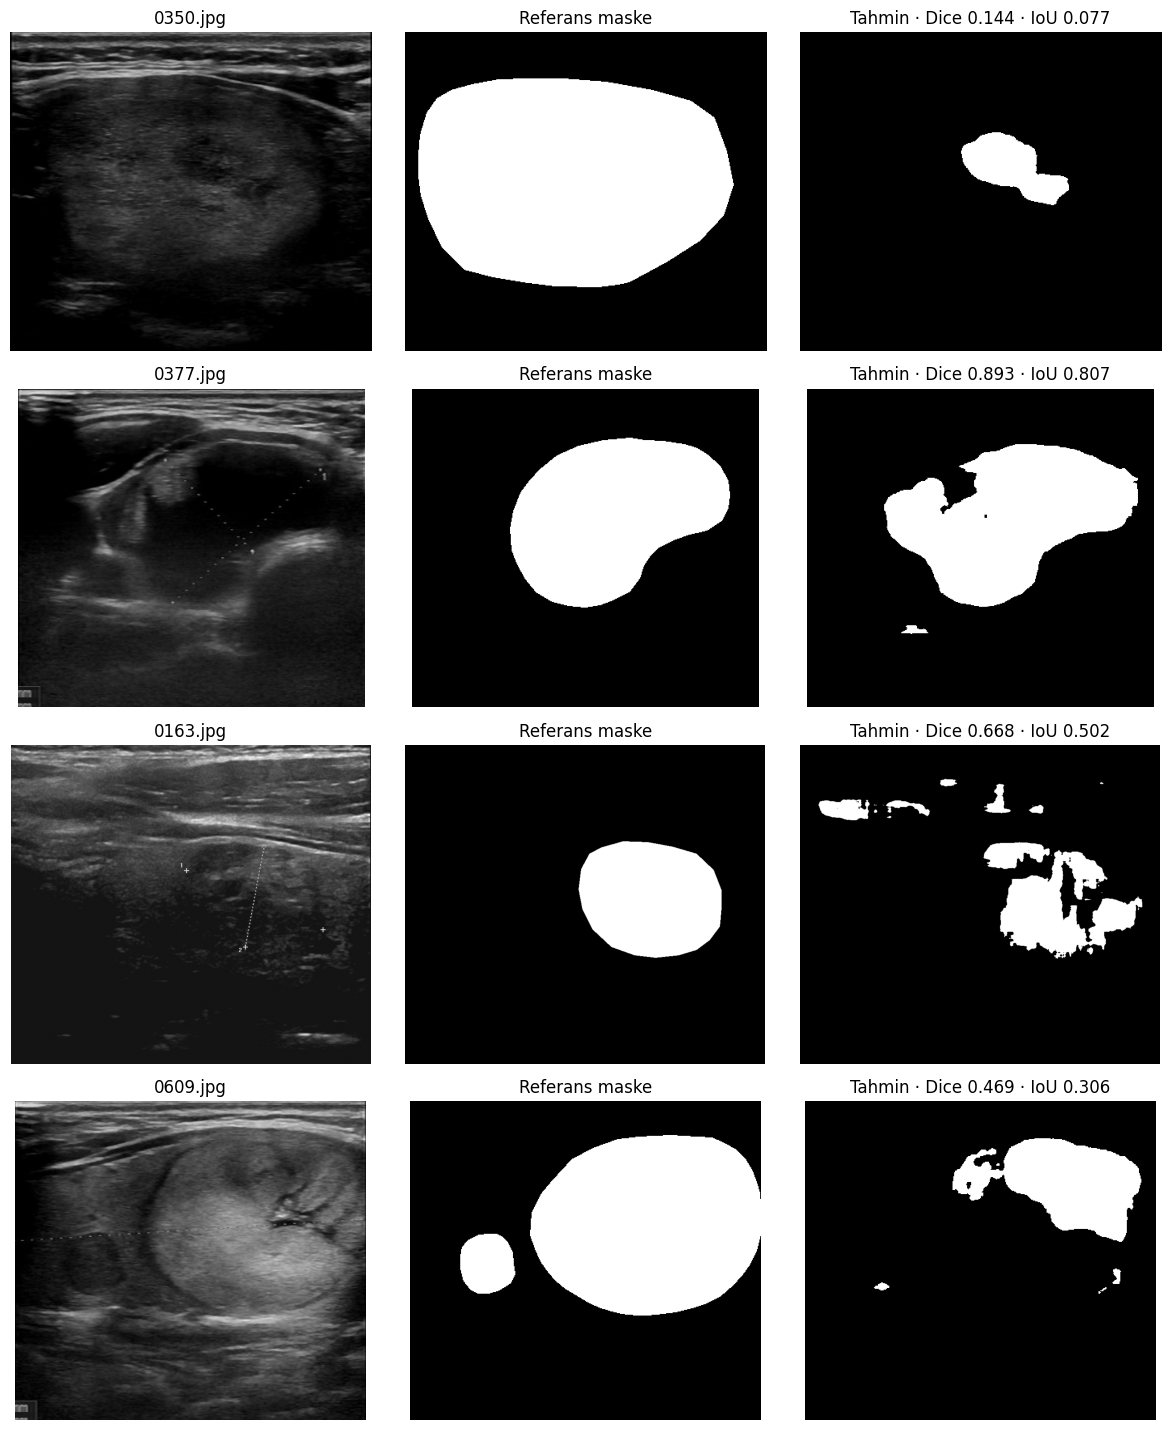

In [8]:
if not (run_dir / "summary.json").is_file():
    raise RuntimeError("Tamamlanmış test özeti bulunamadı.")

scores = summary["all"]
print(f"{summary['label']} | checkpoint: {summary['checkpoint']}")
print(f"Test görüntüleri: {summary['processed_test_images']}/{summary['expected_test_images']}")
print("Kayıt klasörü:", run_dir)
display(pd.DataFrame([{
    "Ortalama Dice": scores["dice_mean"],
    "Ortalama IoU": scores["iou_mean"],
    "Ortalama HD95 (özgün px)": scores["hd95_mean_px"],
    "Sonlu HD95 ort. (özgün px)": scores["hd95_finite_mean_px"],
    "Sonlu olmayan HD95": scores["hd95_nonfinite_cases"],
    "Boş tahmin": scores["empty_predictions"],
}]).round(4))

examples = results.sample(n=min(4, len(results)), random_state=cfg.seed).merge(
    test_table[["split", "filename", "image_path", "mask_path"]],
    on=["split", "filename"], validate="one_to_one",
)
fig, axes = plt.subplots(len(examples), 3, figsize=(12, 3.6 * len(examples)), squeeze=False)
for axes_row, row in zip(axes, examples.itertuples(index=False)):
    image, target = read_image_mask(row.image_path, row.mask_path, cfg)
    with Image.open(prediction_dir / row.prediction_file) as saved:
        prediction = np.array(saved) > 0
    for axis, array, title in zip(
        axes_row, (image, target, prediction),
        (row.filename, "Referans maske", f"Tahmin · Dice {row.dice:.3f} · IoU {row.iou:.3f}"),
    ):
        axis.imshow(array, cmap="gray", vmin=0, vmax=255 if array is image else 1)
        axis.set_title(title)
        axis.axis("off")
fig.tight_layout()
fig.savefig(run_dir / "prediction_comparison.png", dpi=cfg.figure_dpi)
plt.show()